# Chapter 5. Evaluation

## 5.2.1 Fixed-Parameter Search

One fixed primary parameter is selected for each denoiser using the 50 calibration images. The test set is not used.


In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from joblib import Parallel, delayed

# Find the project directory
project_dir = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(project_dir) not in sys.path:
    sys.path.append(str(project_dir))

from src.denoising_config import (
    AD_FIXED_SETTINGS, AD_K_VALUES, BF_FIXED_SETTINGS, BF_SIGMA_COLOR_VALUES,
    METHOD_LABELS, METHOD_ORDER, NLM_FIXED_SETTINGS, NLM_H_VALUES,
    PRIMARY_PARAMETER_NAMES, TV_WEIGHT_VALUES, denoise_with_parameters
)
from src.metrics import calculate_psnr
from src.noise import add_gaussian_noise
from src.utils import load_grayscale_image


In [2]:
# Calibration settings
noise_levels = [2, 4, 6, 8, 10, 12, 15]
seed = 42
num_calibration = 50
n_jobs = 16

calibration_dir = project_dir / "data" / "calibration"
result_dir = project_dir / "results" / "Chapter5_SearchFixedParameter"
result_dir.mkdir(parents=True, exist_ok=True)

# Reuse the calibrated parameter ranges and search steps
calibrated_values = {
    "AD": AD_K_VALUES,
    "TV": TV_WEIGHT_VALUES,
    "BF": BF_SIGMA_COLOR_VALUES,
    "NLM": NLM_H_VALUES
}
search_steps = {"AD": 0.01, "TV": 0.0025, "BF": 0.01, "NLM": 0.0025}

candidate_values = {}
for method in METHOD_ORDER:
    lower = float(np.min(calibrated_values[method]))
    upper = float(np.max(calibrated_values[method]))
    step = search_steps[method]
    candidate_values[method] = np.round(np.arange(lower, upper + step / 2, step), 4)

print("Calibration directory:", calibration_dir)
print("Noise levels (%):", noise_levels)
for method in METHOD_ORDER:
    values = candidate_values[method]
    print(f"{method}: {len(values)} candidates from {values[0]:.4f} to {values[-1]:.4f}")


Calibration directory: D:\MScProject\data\calibration
Noise levels (%): [2, 4, 6, 8, 10, 12, 15]
AD: 22 candidates from 0.0200 to 0.2300
TV: 50 candidates from 0.0100 to 0.1325
BF: 21 candidates from 0.0200 to 0.2200
NLM: 56 candidates from 0.0225 to 0.1600


In [3]:
# Reproduce the Chapter 4 calibration subset
image_files = []
for pattern in ["*.png", "*.jpg", "*.jpeg", "*.bmp", "*.tif", "*.tiff"]:
    image_files.extend(calibration_dir.glob(pattern))

image_files = sorted(set(image_files))
if len(image_files) < num_calibration:
    raise FileNotFoundError(
        f"At least {num_calibration} images are required, but found {len(image_files)} in {calibration_dir}"
    )

split_rng = np.random.default_rng(seed)
shuffled_indices = split_rng.permutation(len(image_files))
calibration_indices = shuffled_indices[:num_calibration]
calibration_files = sorted([image_files[index] for index in calibration_indices])
calibration_images = [(image_file.stem, load_grayscale_image(image_file)) for image_file in calibration_files]

for image_name, clean_image in calibration_images:
    if clean_image.ndim != 2:
        raise ValueError(f"{image_name} is not a grayscale image")
    if clean_image.min() < 0 or clean_image.max() > 1:
        raise ValueError(f"{image_name} is not normalised to [0, 1]")

print("Number of calibration images:", len(calibration_images))
print("First image:", calibration_images[0][0])
print("Last image:", calibration_images[-1][0])


Number of calibration images: 50
First image: 004
Last image: 198


## Fixed-Parameter Search

Each candidate is evaluated across the seven calibration noise levels. The value with the highest overall mean PSNR is selected.


In [4]:
# Combine one candidate with the fixed secondary settings
def make_parameters(method, value):
    value = float(value)

    if method == "AD":
        parameters = AD_FIXED_SETTINGS.copy()
        parameters["kappa"] = value
        return parameters
    if method == "TV":
        return {"weight": value}
    if method == "BF":
        parameters = BF_FIXED_SETTINGS.copy()
        parameters["sigma_color"] = value
        return parameters

    parameters = NLM_FIXED_SETTINGS.copy()
    parameters["h"] = value
    return parameters


def evaluate_case(method, image_name, clean_image, noise_percent):
    noisy_image = add_gaussian_noise(clean_image, sigma=noise_percent / 100, seed=seed).astype(np.float32)
    rows = []

    for value in candidate_values[method]:
        parameters = make_parameters(method, value)
        denoised_image = denoise_with_parameters(noisy_image, method, parameters)

        if denoised_image.shape != clean_image.shape:
            raise ValueError(f"{method} returned an unexpected image shape")
        if not np.isfinite(denoised_image).all():
            raise ValueError(f"{method} returned a non-finite value")

        rows.append({
            "method": method,
            "image": image_name,
            "true_noise_percent": noise_percent,
            "parameter_value": float(value),
            "psnr": calculate_psnr(clean_image, denoised_image)
        })

    return rows


In [5]:
# Run the four searches
search_outputs = Parallel(n_jobs=n_jobs, prefer="threads", verbose=5)(
    delayed(evaluate_case)(method, image_name, clean_image, noise_percent)
    for method in METHOD_ORDER
    for noise_percent in noise_levels
    for image_name, clean_image in calibration_images
)

search_results = pd.DataFrame([row for case_rows in search_outputs for row in case_rows])

expected_rows = num_calibration * len(noise_levels) * sum(len(candidate_values[method]) for method in METHOD_ORDER)
if len(search_results) != expected_rows:
    raise RuntimeError(f"Expected {expected_rows} results, but obtained {len(search_results)}")
if not np.isfinite(search_results[["parameter_value", "psnr"]]).all().all():
    raise ValueError("The search contains a non-finite result")

print("Completed calibration cases:", len(search_outputs))
print("Completed PSNR measurements:", len(search_results))
display(search_results.head())


[Parallel(n_jobs=16)]: Using backend ThreadingBackend with 16 concurrent workers.
[Parallel(n_jobs=16)]: Done  40 tasks      | elapsed:   16.7s
[Parallel(n_jobs=16)]: Done 130 tasks      | elapsed:   43.8s
[Parallel(n_jobs=16)]: Done 256 tasks      | elapsed:  1.3min
[Parallel(n_jobs=16)]: Done 418 tasks      | elapsed:  2.7min
[Parallel(n_jobs=16)]: Done 616 tasks      | elapsed:  6.2min
[Parallel(n_jobs=16)]: Done 850 tasks      | elapsed: 16.1min
[Parallel(n_jobs=16)]: Done 1120 tasks      | elapsed: 27.6min


Completed calibration cases: 1400
Completed PSNR measurements: 52150


[Parallel(n_jobs=16)]: Done 1400 out of 1400 | elapsed: 30.0min finished


,method,image,true_noise_percent,parameter_value,psnr
0,AD,004,2,0.02,37.581068
1,AD,004,2,0.03,37.043521
2,AD,004,2,0.04,35.996098
3,AD,004,2,0.05,35.072473
4,AD,004,2,0.06,34.330443


In [6]:
# Select the best fixed parameter for each method
search_summary = (
    search_results.groupby(["method", "parameter_value"], as_index=False)["psnr"]
    .mean().rename(columns={"psnr": "overall_mean_psnr"})
)

best_indices = search_summary.groupby("method")["overall_mean_psnr"].idxmax()
selected_parameters = search_summary.loc[best_indices].copy()
selected_parameters["order"] = selected_parameters["method"].map(
    {method: index for index, method in enumerate(METHOD_ORDER)}
)
selected_parameters = selected_parameters.sort_values("order").reset_index(drop=True)

def reached_boundary(row):
    values = candidate_values[row["method"]]
    return np.isclose(row["parameter_value"], values[0]) or np.isclose(row["parameter_value"], values[-1])

selected_parameters["at_search_boundary"] = selected_parameters.apply(reached_boundary, axis=1)
selected_parameters["Method"] = selected_parameters["method"].map(METHOD_LABELS)
selected_parameters["Parameter"] = selected_parameters["method"].map(PRIMARY_PARAMETER_NAMES)

selected_table = selected_parameters[
    ["Method", "Parameter", "parameter_value", "overall_mean_psnr", "at_search_boundary"]
].rename(columns={
    "parameter_value": "Selected value",
    "overall_mean_psnr": "Overall mean PSNR (dB)",
    "at_search_boundary": "At search boundary"
})

display(selected_table.round(4))
if selected_parameters["at_search_boundary"].any():
    print("Warning: expand the affected search range before finalising it.")


,Method,Parameter,Selected value,Overall mean PSNR (dB),At search boundary
0,Anisotropic diffusion,kappa,0.1300,27.1876,False
1,Total variation,weight,0.0675,27.4851,False
2,Bilateral filtering,sigma_color,0.1000,25.4634,False
3,Non-local means,h,0.1050,27.0479,False


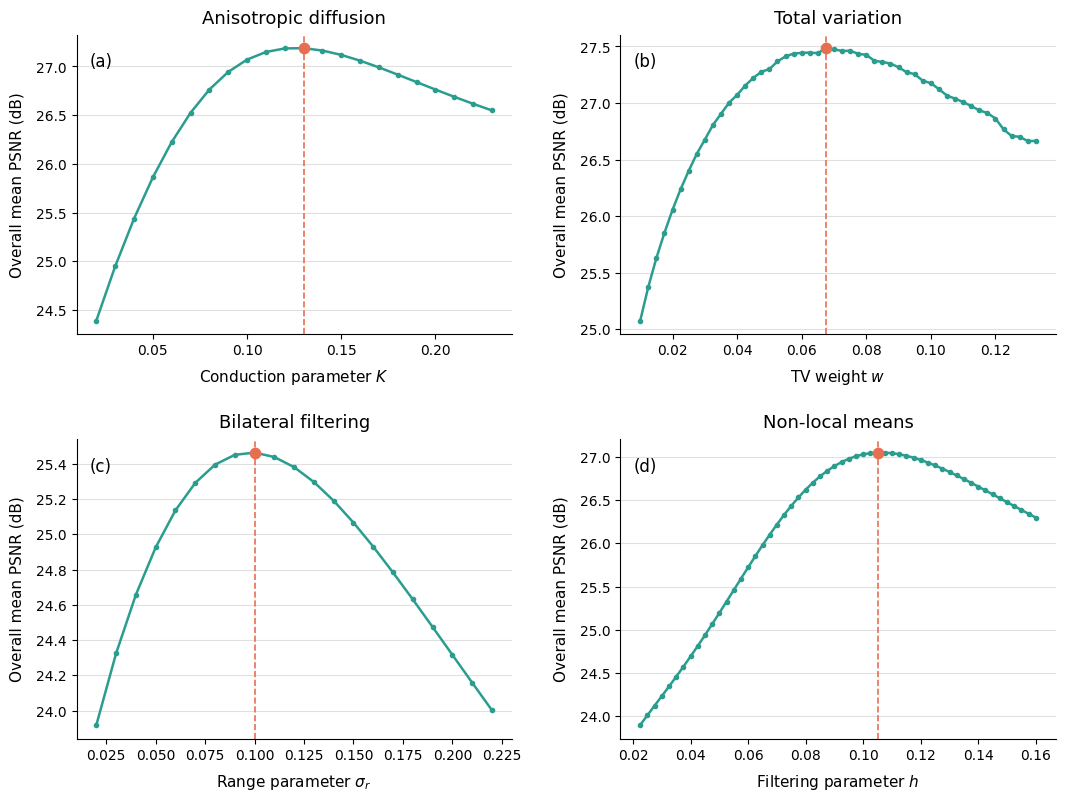

In [7]:
# Plot the fixed-parameter searches
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
axis_labels = {
    "AD": r"Conduction parameter $K$",
    "TV": r"TV weight $w$",
    "BF": r"Range parameter $\sigma_r$",
    "NLM": r"Filtering parameter $h$"
}

for panel, (ax, method) in enumerate(zip(axes.ravel(), METHOD_ORDER)):
    current = search_summary[search_summary["method"] == method]
    selected = selected_parameters[selected_parameters["method"] == method].iloc[0]

    ax.plot(current["parameter_value"], current["overall_mean_psnr"],
            color="#2a9d8f", marker="o", markersize=3, linewidth=1.8)
    ax.scatter(selected["parameter_value"], selected["overall_mean_psnr"],
               color="#e76f51", s=55, zorder=3)
    ax.axvline(selected["parameter_value"], color="#e76f51", linestyle="--", linewidth=1.2)

    ax.set_title(METHOD_LABELS[method], fontsize=13, pad=8)
    ax.set_xlabel(axis_labels[method], fontsize=11, labelpad=7)
    ax.set_ylabel("Overall mean PSNR (dB)", fontsize=11, labelpad=8)
    ax.tick_params(axis="both", labelsize=10)
    ax.grid(axis="y", color="#d9d9d9", linewidth=0.8, alpha=0.8)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.text(0.03, 0.94, f"({chr(97 + panel)})",
            transform=ax.transAxes, ha="left", va="top", fontsize=12)

fig.subplots_adjust(left=0.09, right=0.98, top=0.96, bottom=0.08, wspace=0.25, hspace=0.35)
fig.savefig(result_dir / "fixed_parameter_search.png", dpi=300, bbox_inches="tight")
plt.show()
